In [ ]:
!pip install vaderSentiment

In [ ]:
"""
Grand Hyatt Mumbai - Google review analysis
Descriptive, sentiment, diagnostic, text mining, predictive, prescriptive.

Input : the four scraped files (google 1.csv ... google 4.csv)
Output: printed tables + PNG charts + clean CSVs in ./out

pip install pandas numpy scipy scikit-learn matplotlib vaderSentiment wordcloud
(wordcloud is optional)
"""
import glob
import os
import re

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import stats
from sklearn.decomposition import NMF
from sklearn.dummy import DummyClassifier
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import RepeatedStratifiedKFold, cross_validate
from sklearn.pipeline import make_pipeline
from vaderSentiment.vaderSentiment import SentimentIntensityAnalyzer

DATA_GLOB = "google*.csv"
OUT = "out"
SHOW = True
TODAY = pd.Timestamp("2026-10-22")
BLUE, ORG, GRAY = "#2a78d6", "#eb6834", "#8a8a85"

os.makedirs(OUT, exist_ok=True)
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)
pd.set_option("display.max_colwidth", 90)


def head(t):
    print("\n" + t.upper())


def save(name):
    plt.tight_layout()
    plt.savefig(f"{OUT}/{name}.png", dpi=150)
    if SHOW:
        plt.show()
    plt.close()


def style(ax):
    for s in ("top", "right"):
        ax.spines[s].set_visible(False)
    ax.grid(axis="y", alpha=0.25)

1. load and clean

In [ ]:
# The scraper shifted columns between files, so we never rely on position.
# Each row is parsed by looking at column-name prefixes and cell contents.

SMART = {0x2019: "'", 0x2018: "'", 0x201C: '"', 0x201D: '"', 0x2013: "-",
         0x2014: "-", 0x2026: " ", 0xA0: " "}


def norm(t):
    t = str(t).translate(SMART)
    t = t.encode("ascii", "ignore").decode()
    t = re.sub(r"([a-z])\.([A-Z])", r"\1. \2", t)
    return re.sub(r"\s+", " ", t).strip()


def pcols(row, prefix):
    return [c for c in row.index if c == prefix or c.startswith(prefix + " ")]


def vals(row, prefix):
    return [row[c] for c in pcols(row, prefix) if isinstance(row[c], str) and row[c].strip()]


def age_years(s):
    """'11 months ago on', 'Edited 2 years ago', 'a year ago' -> years as float"""
    if not isinstance(s, str):
        return np.nan
    m = re.search(r"(\d+|a|an)\s+(day|week|month|year)s?", s.lower())
    if not m:
        return np.nan
    n = 1 if m.group(1) in ("a", "an") else int(m.group(1))
    return n * {"day": 1 / 365, "week": 7 / 365, "month": 1 / 12, "year": 1}[m.group(2)]


def build_text(cells):
    """Reviews are split over several columns, some are truncated copies of
    the full text. Keep longest first, drop anything already contained."""
    cs = sorted({norm(c) for c in cells if norm(c)}, key=len, reverse=True)
    keep = []
    for c in cs:
        core = c.strip(". ").lower()
        if core and not any(core in k.lower() for k in keep):
            keep.append(c)
    return " ".join(keep)


KNOWN_RESP = ["Robert Dallimore", "Dietmar Kielnhofer", "Sumit Datta",
              "Sonale Zagade", "Deepak Khusalani"]


def parse_row(r, fid):
    d = {"file": fid}
    d["name"] = norm(r.get("DHIhE", ""))
    d["rating"] = float(str(r["GDWaad"]).split("/")[0])
    lab = str(r.get("iUtr1", ""))
    d["age_label"] = norm(lab)
    d["edited"] = lab.lower().startswith("edited")
    d["age_y"] = age_years(lab)
    d["source"] = norm(r["YhR3n"]) if "YhR3n" in r.index and isinstance(r["YhR3n"], str) else "Google"

    trip = r.get("ThUm5b")
    toks = [x for x in re.split(r"\s*[^\w\s-]+\s*", trip) if x] if isinstance(trip, str) else []
    d["purpose"] = next((x for x in toks if x in ("Business", "Vacation")), "Unknown")
    d["party"] = next((x for x in toks if x in ("Solo", "Friends", "Family", "Couple")), "Unknown")

    for suf in ("", " 2", " 3"):
        lb, v = r.get("uTU5Ac" + suf), r.get("dA5Vzb" + suf)
        if isinstance(lb, str) and lb in ("Rooms", "Service", "Location") and pd.notna(v):
            d[lb.lower()] = float(v)

    hl = r.get("X4nL7d")
    hl = hl if isinstance(hl, str) and r.get("iTppcd") == "Hotel highlights" else ""
    d["tags"] = [x for x in re.split(r"\s*[^\w\s-]+\s*", hl) if x]

    d["text"] = build_text(vals(r, "K7oBsc"))

    d["n_photo"] = len(vals(r, "x7VXS src")) + (int(r["hXNk4d"]) if pd.notna(r.get("hXNk4d")) else 0)

    resp = vals(r, "JOzlvd")
    d["has_resp"] = isinstance(r.get("n7uVJf"), str) or isinstance(r.get("a0th8b"), str)
    d["resp"] = norm(" ".join(resp)) if d["has_resp"] else ""
    d["resp_age_y"] = age_years(r.get("a0th8b"))
    d["responder"] = next((n for n in KNOWN_RESP if n in d["resp"]), "Unknown" if d["has_resp"] else "")
    return d


rows = []
for i, f in enumerate(sorted(glob.glob(DATA_GLOB)), 1):
    raw = pd.read_csv(f)
    rows += [parse_row(r, i) for _, r in raw.iterrows()]
    print(f, raw.shape)

df = pd.DataFrame(rows)
print("raw rows:", len(df))

# the same review shows up twice inside a file and across files
df["len"] = df["text"].str.len()
df["key"] = df["name"].str.lower() + "|" + df["rating"].astype(str) + "|" + df["age_label"].str.replace(r"(?i)edited |on$", "", regex=True).str.strip()
df = df.sort_values("len", ascending=False).drop_duplicates("key").sort_index().reset_index(drop=True)
print("unique reviews:", len(df))

# edited reviews show the edit date, but a reply cannot be older than the review
m = df["edited"] & df["resp_age_y"].notna()
df.loc[m, "age_y"] = df.loc[m, ["age_y", "resp_age_y"]].max(axis=1)
df["date_est"] = TODAY - pd.to_timedelta(df["age_y"] * 365, unit="D")
df["era"] = pd.cut(df["age_y"], [0, 1, 3, 6, 99], labels=["<1y", "1-3y", "3-6y", "6y+"], right=False)
df["words"] = df["text"].str.split().str.len()
df["good"] = df["rating"] >= 4

# one review is about a hotel group controversy, not a stay
df["offtopic"] = df["text"].str.contains(r"Kaziranga|Juniper|ethical and environmental", case=False)
print("off-topic reviews flagged:", int(df["offtopic"].sum()))

google (1).csv (13, 31)
google (2).csv (14, 44)
google (3).csv (22, 29)
google (4).csv (15, 33)
raw rows: 64
unique reviews: 49
off-topic reviews flagged: 1


2. descriptive analysis


DESCRIPTIVE: RATINGS
n = 49 | mean 4.53 | median 5.0 | std 0.89
share 4-5 stars: 91.8 % | share 5 stars: 69.4 %
        count   pct
rating             
1.0         1   2.0
2.0         2   4.1
3.0         1   2.0
4.0        11  22.4
5.0        34  69.4

DESCRIPTIVE: SUB-RATINGS (ONLY SOME REVIEWERS FILLED THESE)
           n  mean  min
rooms     23  4.52  3.0
service   26  4.42  1.0
location  22  4.36  3.0

DESCRIPTIVE: WHO IS REVIEWING
          count  mean
purpose              
Business     19  4.47
Unknown      26  4.54
Vacation      4  4.75
         count  mean
party               
Couple       1  4.00
Family       6  4.67
Friends      4  5.00
Solo         9  4.56
Unknown     29  4.45
source
Google      48
Trip.com     1
Name: count, dtype: int64

DESCRIPTIVE: REVIEW TAGS (GOOGLE 'HOTEL HIGHLIGHTS')
tags
Luxury          14
Great view       7
Quiet            6
Great value      6
High-tech        4
Kid-friendly     4
Romantic         1
Name: count, dtype: int64

DESCRIPTIVE: OVER TI

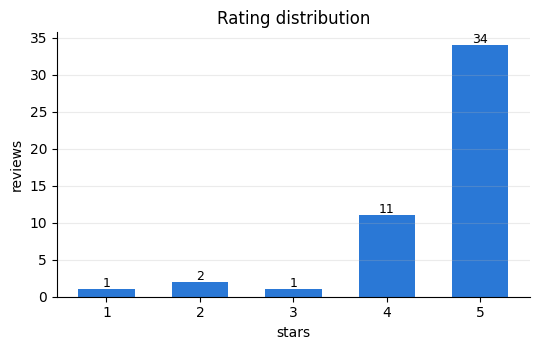

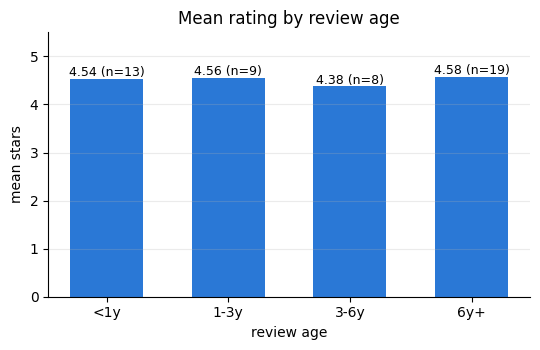

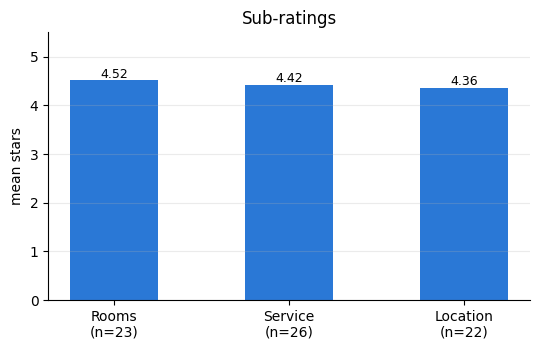

In [ ]:
head("descriptive: ratings")
n = len(df)
print("n =", n, "| mean", round(df.rating.mean(), 2), "| median", df.rating.median(), "| std", round(df.rating.std(), 2))
print("share 4-5 stars:", round(df.good.mean() * 100, 1), "% | share 5 stars:", round((df.rating == 5).mean() * 100, 1), "%")
print(df.rating.value_counts().sort_index().rename("count").to_frame().assign(pct=lambda x: (x["count"] / n * 100).round(1)))

head("descriptive: sub-ratings (only some reviewers filled these)")
subs = ["rooms", "service", "location"]
print(pd.DataFrame({"n": df[subs].notna().sum(), "mean": df[subs].mean().round(2), "min": df[subs].min()}))

head("descriptive: who is reviewing")
print(df.groupby("purpose").rating.agg(["count", "mean"]).round(2))
print(df.groupby("party").rating.agg(["count", "mean"]).round(2))
print(df.source.value_counts())

head("descriptive: review tags (Google 'hotel highlights')")
tags = df["tags"].explode().dropna().value_counts()
print(tags)

head("descriptive: over time (Google gives coarse relative dates)")
print(df.groupby("era", observed=True).agg(n=("rating", "size"), mean=("rating", "mean"), words=("words", "mean")).round(2))

head("descriptive: review length (words)")
print(df.words.describe().round(1))
print("avg words, 5 star vs <5 star:", round(df[df.rating == 5].words.mean(), 1), "vs", round(df[df.rating < 5].words.mean(), 1))

fig, ax = plt.subplots(figsize=(5.5, 3.6))
c = df.rating.value_counts().reindex([1, 2, 3, 4, 5], fill_value=0)
ax.bar(c.index.astype(str), c.values, color=BLUE, width=0.6)
for x, v in zip(c.index.astype(str), c.values):
    ax.text(x, v + 0.3, str(v), ha="center", fontsize=9)
ax.set_xlabel("stars")
ax.set_ylabel("reviews")
ax.set_title("Rating distribution")
style(ax)
save("01_rating_dist")

fig, ax = plt.subplots(figsize=(5.5, 3.6))
g = df.groupby("era", observed=True).rating.agg(["mean", "size"])
ax.bar(g.index.astype(str), g["mean"], color=BLUE, width=0.6)
for x, (mu, k) in zip(g.index.astype(str), g.values):
    ax.text(x, mu + 0.05, f"{mu:.2f} (n={int(k)})", ha="center", fontsize=9)
ax.set_ylim(0, 5.5)
ax.set_xlabel("review age")
ax.set_ylabel("mean stars")
ax.set_title("Mean rating by review age")
style(ax)
save("02_rating_by_era")

fig, ax = plt.subplots(figsize=(5.5, 3.6))
sm = df[subs].mean()
ax.bar([s.title() + f"\n(n={int(df[s].notna().sum())})" for s in subs], sm.values, color=BLUE, width=0.5)
for i, v in enumerate(sm.values):
    ax.text(i, v + 0.05, f"{v:.2f}", ha="center", fontsize=9)
ax.set_ylim(0, 5.5)
ax.set_ylabel("mean stars")
ax.set_title("Sub-ratings")
style(ax)
save("03_subratings")

3. sentiment analysis


SENTIMENT: OVERALL
senti
positive    48
negative     1
neutral      0
Name: count, dtype: int64
mean compound: 0.888

SENTIMENT: BY STAR RATING
        count   mean    min    max
rating                            
1.0         1  0.564  0.564  0.564
2.0         2  0.191 -0.572  0.954
3.0         1  0.872  0.872  0.872
4.0        11  0.857  0.700  0.974
5.0        34  0.949  0.778  0.996

spearman(stars, text sentiment), off-topic excluded: rho=0.55 p=0.0001

SENTIMENT: TEXT AND STARS DISAGREE
         name  rating  vader  offtopic                                                                                                           text
  Arno Vogels     2.0 0.9536     False 2nd stay in this hotel for business. Breakfast is ok for Indian nationals, but not adapted to Europeans, the s
Ruqqaiya Khan     1.0 0.5639      True I choose hotels based on their ethical and environmental track records. The ongoing dispute surrounding Junipe
Pranav Kelkar     3.0 0.8720     False Only issue is

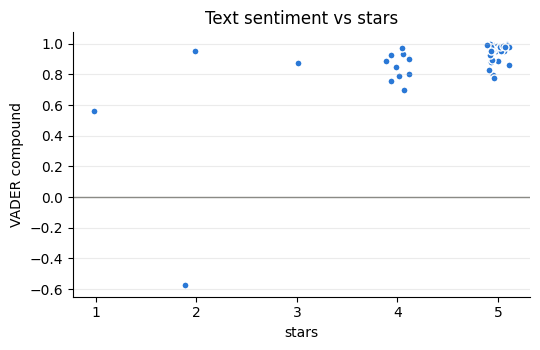

In [ ]:
# VADER is a rule-based lexicon model made for short informal text, works
# without training data. Compound score runs from -1 (negative) to +1.
sia = SentimentIntensityAnalyzer()
df["vader"] = df["text"].apply(lambda t: sia.polarity_scores(t)["compound"])
df["senti"] = pd.cut(df["vader"], [-1.01, -0.05, 0.05, 1.01], labels=["negative", "neutral", "positive"])

head("sentiment: overall")
print(df.senti.value_counts())
print("mean compound:", round(df.vader.mean(), 3))

head("sentiment: by star rating")
print(df.groupby("rating").vader.agg(["count", "mean", "min", "max"]).round(3))

ok = ~df.offtopic
rho, p = stats.spearmanr(df.loc[ok, "rating"], df.loc[ok, "vader"])
print("\nspearman(stars, text sentiment), off-topic excluded: rho=%.2f p=%.4f" % (rho, p))

head("sentiment: text and stars disagree")
mis = df[((df.rating >= 4) & (df.vader < 0.3)) | ((df.rating <= 3) & (df.vader > 0.3))]
print(mis[["name", "rating", "vader", "offtopic", "text"]].assign(text=lambda x: x.text.str[:110]).to_string(index=False))

head("sentiment: by review age and by trip purpose")
print(df.groupby("era", observed=True).vader.mean().round(3))
print(df.groupby("purpose").vader.mean().round(3))

fig, ax = plt.subplots(figsize=(5.5, 3.6))
for r_ in [1, 2, 3, 4, 5]:
    y = df.loc[df.rating == r_, "vader"]
    ax.scatter(np.full(len(y), r_) + np.random.RandomState(r_).uniform(-0.12, 0.12, len(y)), y, s=26, color=BLUE, edgecolor="white", linewidth=1)
ax.axhline(0, color=GRAY, lw=1)
ax.set_xlabel("stars")
ax.set_ylabel("VADER compound")
ax.set_title("Text sentiment vs stars")
style(ax)
save("04_sentiment_vs_stars")

4. aspect based sentiment


ASPECT BASED SENTIMENT (SENTENCE LEVEL)
                        reviews  sentences  mean  pos_pct  neg_pct  complaint_pct
asp                                                                              
value for money               3          4  0.33    50.00     0.00          25.00
check-in and billing          8         11  0.35    63.64    18.18          18.18
upkeep and cleanliness       14         19  0.35    63.16    10.53          47.37
room                         26         42  0.36    59.52     4.76          14.29
events and facilities        20         35  0.41    65.71     0.00           2.86
food and dining              35         54  0.51    75.93     3.70           9.26
staff and service            32         58  0.52    77.59     5.17           8.62
location                     15         18  0.53    94.44     0.00          11.11
ambience and design          16         19  0.56    84.21     0.00          10.53


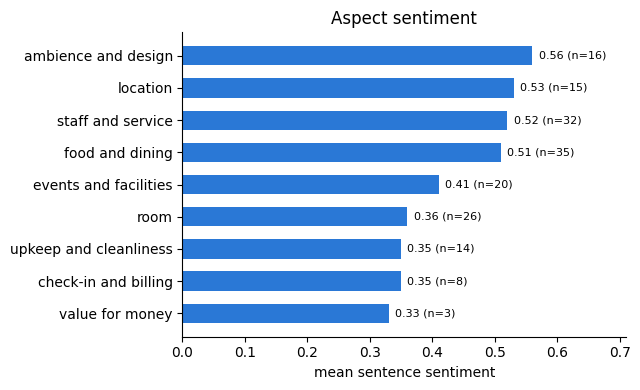


ASPECT BY REVIEW AGE (MEAN SENTENCE SENTIMENT)
era                      <1y  1-3y  3-6y   6y+
asp                                           
ambience and design     0.89  0.75  0.40  0.55
check-in and billing    0.75  0.53  0.38  0.12
events and facilities   0.54  0.40  0.47  0.36
food and dining         0.70  0.48  0.51  0.45
location                0.61  0.25  0.69  0.54
room                    0.35  0.50  0.49  0.29
staff and service       0.66  0.51  0.23  0.45
upkeep and cleanliness  0.47  0.25  0.18  0.31
value for money         0.67  0.00   NaN   NaN


In [ ]:
# Idea: split each review into sentences, tag a sentence with the aspects it
# talks about (keyword lists), score that sentence, then average per aspect.
ASP = {
    "room": r"\b(room(?!\s+service)\w*|suite\w*|bed\w*|bath\w*|washroom\w*|apartment\w*|residence\w*|carpet\w*|amenit\w*)\b",
    "staff and service": r"\b(staff|service|team|manager|reception\w*|concierge|housekeeping|assist\w*|helpful|courteous|hospitality|waiter\w*|valet|polite|friendly)\b",
    "check-in and billing": r"\b(check[- ]?in|check[- ]?out|front desk|invoice|bill\w*|queue|receipt)\b",
    "food and dining": r"\b(food|breakfast|buffet|restaurant\w*|dinner|lunch|cuisine|dish\w*|dessert\w*|coffee|cake|chef|dining|brunch|menu|sushi|bar\w*)\b",
    "location": r"\b(location|airport|highway|bkc|traffic|located|situated|connectivity)\b",
    "upkeep and cleanliness": r"\b(clean\w*|dirty|spotless|tidy|maintain\w*|old|worn|musty|dank|smell|odou?r|mosquito\w*|renovat\w*|revamp|dated)\b",
    "ambience and design": r"\b(ambien\w*|ambiance|decor|interior\w*|lobby|view\w*|architecture|design\w*|lighting|garden|lawn|art|posh)\b",
    "value for money": r"\b(price\w*|value|expensive|afford\w*|unaffordable|cost\w*|worth)\b",
    "events and facilities": r"\b(conference\w*|event\w*|banquet|ballroom|hall\w*|wedding|meeting\w*|pool|gym|fitness|parking|mall|shopping)\b",
}
CUE = re.compile(r"\b(old|worn|musty|dank|slow|mosquito\w*|mosquitos|expensive|unaffordable|difficult|revamp|outdated|dirty|pathetic|worst|issue|downside|negative|hiccup\w*|waited|mark ?up|bother\w*|menace|least expected|unavailab\w*|reduced a star|closed sharp|not well made|not adapted)\b", re.I)


def sents(t):
    return [s for s in re.split(r"(?<=[.!?])\s+", t) if len(s) > 3]


recs = []
for i, r in df.iterrows():
    for s in sents(r.text):
        sc = sia.polarity_scores(s)["compound"]
        tagged = [a for a, rx in ASP.items() if re.search(rx, s, re.I)]
        recs.append({"i": i, "name": r["name"], "rating": r.rating, "off": r.offtopic, "sent": s,
                     "score": sc, "asp": tagged or ["other"],
                     "complaint": (sc <= -0.3) or bool(CUE.search(s))})
sd = pd.DataFrame(recs)
# VADER compound on a whole review drifts to +1 as the text gets longer,
# so the average of sentence scores is a fairer per-review number
df["sent_mean"] = sd.groupby("i").score.mean()
sd = sd[~sd.off]
sx = sd.explode("asp")

head("aspect based sentiment (sentence level)")
at = sx[sx.asp != "other"].groupby("asp").agg(
    reviews=("i", "nunique"), sentences=("sent", "size"), mean=("score", "mean"),
    pos_pct=("score", lambda s: (s >= 0.05).mean() * 100),
    neg_pct=("score", lambda s: (s <= -0.05).mean() * 100),
    complaint_pct=("complaint", lambda s: s.mean() * 100)).round(2).sort_values("mean")
print(at)
at.to_csv(f"{OUT}/aspect_table.csv")

fig, ax = plt.subplots(figsize=(6.5, 4))
a = at.sort_values("mean")
ax.barh(a.index, a["mean"], color=[BLUE if v >= 0 else ORG for v in a["mean"]], height=0.6)
for y, (v, k) in enumerate(zip(a["mean"], a["reviews"])):
    ax.text(v + 0.01, y, f"{v:.2f} (n={k})", va="center", fontsize=8)
ax.set_xlim(0, a["mean"].max() + 0.15)
ax.set_xlabel("mean sentence sentiment")
ax.set_title("Aspect sentiment")
ax.spines[["top", "right"]].set_visible(False)
save("05_aspect_sentiment")

head("aspect by review age (mean sentence sentiment)")
sx["era"] = sx["i"].map(df["era"])
print(sx[sx.asp != "other"].pivot_table(index="asp", columns="era", values="score", aggfunc="mean", observed=True).round(2))

5. diagnostic analysis: why are some ratings lower


DIAGNOSTIC: WHAT DO COMPLAINT SENTENCES SAY
complaint sentences: 20 from 13 reviews
asp
room                      6
staff and service         4
upkeep and cleanliness    3
location                  2
food and dining           2
check-in and billing      2
value for money           1
Name: complaints, dtype: int64

[4 star | upkeep and cleanliness | -0.65] Do not mean to nitpick but the mosquitos were a menace.
[2 star | staff and service | -0.57] The service is same pathetic for years.
[2 star | check-in and billing | -0.47] This time they changed the currency of my creditcard to ILS (Israelean Schequel) no idea why they do that as I am based in Europe and didn't even asked for a ch
[4 star | room | -0.44] The hotel has a slightly worn-out look and feel, especially in the Residences block.
[2 star | staff and service | -0.27] The hotel Grand Hyatt has worst food and service.
[2 star | food and dining | -0.16] Breakfast is ok for Indian nationals, but not adapted to Europeans, the sele

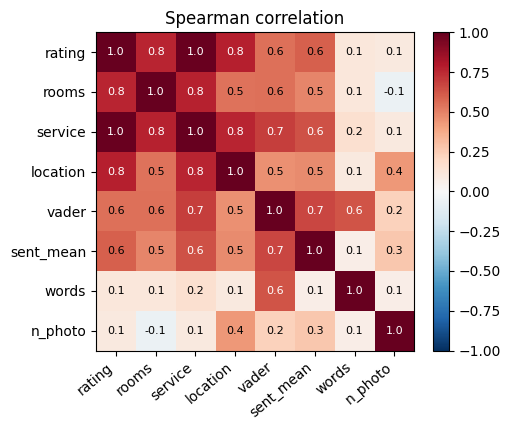


DIAGNOSTIC: HYPOTHESIS TESTS (N IS SMALL, READ P-VALUES LOOSELY)
business vs vacation stars: n=19/4 p=0.629
reviews 3y+ old vs newer, stars: mean 4.52 vs 4.55 p=0.719
spearman(age, stars): rho=-0.06 p=0.702
words, <5 star vs 5 star: median 63 vs 64 p=0.454
owner replied, old vs new:
 has_resp  False  True 
age_y                 
False         3     19
True          0     27
fisher p=0.084

DIAGNOSTIC: OWNER REPLIES
reply rate: 93.9 %
rating
1.0    1.00
2.0    1.00
3.0    1.00
4.0    0.91
5.0    0.94
Name: reply_rate, dtype: float64
responder  Dietmar Kielnhofer  Robert Dallimore  Sonale Zagade  Sumit Datta  Unknown  no reply
era                                                                                           
<1y                         0                 9              0            3        0         1
1-3y                        2                 2              0            2        1         2
3-6y                        6                 0              2            0      

In [ ]:
head("diagnostic: what do complaint sentences say")
cp = sx[(sx.asp != "other") & sx.complaint].drop_duplicates("sent")
print("complaint sentences:", cp.sent.nunique(), "from", cp.i.nunique(), "reviews")
print(cp.groupby("asp").size().sort_values(ascending=False).rename("complaints"))
print()
for _, r in cp.sort_values("score").iterrows():
    print(f"[{int(r.rating)} star | {r.asp} | {r.score:+.2f}] {r.sent[:160]}")

head("diagnostic: hidden complaints inside 4-5 star reviews")
hid = sd[(sd.rating >= 4) & sd.complaint].drop_duplicates("sent")
print(len(hid), "sentences from", hid.i.nunique(), "reviews")
for _, r in hid.iterrows():
    print(f"- {r['name']} ({int(r.rating)}): {r.sent[:150]}")

head("diagnostic: sub-rating gaps in reviews below 5 stars")
print(df[df.rating < 5][["name", "rating"] + subs].dropna(subset=subs, how="all").to_string(index=False))

head("diagnostic: correlations (spearman)")
cm = df.loc[ok, ["rating", "rooms", "service", "location", "vader", "sent_mean", "words", "n_photo"]].corr(method="spearman").round(2)
print(cm)
print("note: whole-review vader rises with length (corr with words above); sent_mean does not have that problem")

fig, ax = plt.subplots(figsize=(5.2, 4.4))
im = ax.imshow(cm.values, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(cm)), cm.columns, rotation=40, ha="right")
ax.set_yticks(range(len(cm)), cm.index)
for i in range(len(cm)):
    for j in range(len(cm)):
        v = cm.values[i, j]
        if not np.isnan(v):
            ax.text(j, i, f"{v:.1f}", ha="center", va="center", fontsize=8, color="white" if abs(v) > 0.6 else "black")
plt.colorbar(im, fraction=0.046)
ax.set_title("Spearman correlation")
save("06_corr")

head("diagnostic: hypothesis tests (n is small, read p-values loosely)")
bz, vc = df[df.purpose == "Business"].rating, df[df.purpose == "Vacation"].rating
if len(vc) >= 3:
    u = stats.mannwhitneyu(bz, vc)
    print("business vs vacation stars: n=%d/%d p=%.3f" % (len(bz), len(vc), u.pvalue))
old, new = df[df.age_y >= 3].rating, df[df.age_y < 3].rating
u = stats.mannwhitneyu(old, new)
print("reviews 3y+ old vs newer, stars: mean %.2f vs %.2f p=%.3f" % (old.mean(), new.mean(), u.pvalue))
rho, p = stats.spearmanr(df.age_y, df.rating)
print("spearman(age, stars): rho=%.2f p=%.3f" % (rho, p))
lo, hi = df[df.rating < 5].words, df[df.rating == 5].words
u = stats.mannwhitneyu(lo, hi)
print("words, <5 star vs 5 star: median %.0f vs %.0f p=%.3f" % (lo.median(), hi.median(), u.pvalue))
ct = pd.crosstab(df.age_y >= 3, df.has_resp)
print("owner replied, old vs new:\n", ct)
if ct.shape == (2, 2):
    print("fisher p=%.3f" % stats.fisher_exact(ct)[1])

head("diagnostic: owner replies")
print("reply rate:", round(df.has_resp.mean() * 100, 1), "%")
print(df.groupby("rating").has_resp.mean().round(2).rename("reply_rate"))
print(pd.crosstab(df.era, df.responder.replace("", "no reply")))


def jac(a, b):
    a, b = set(a.lower().split()), set(b.lower().split())
    return len(a & b) / max(1, len(a | b))


rp = df[df.has_resp & (df.resp.str.len() > 0)]
pairs = [jac(a, b) for i, a in enumerate(rp.resp) for b in rp.resp.iloc[i + 1:]]
print("replies:", len(rp), "| avg words:", round(rp.resp.str.split().str.len().mean(), 1),
      "| mean pairwise word overlap (templated if high): %.2f" % np.mean(pairs))
low = df[(df.rating <= 3) & df.has_resp]
for _, r in low.iterrows():
    print(f"reply to {int(r.rating)} star by {r['name']}: {r.resp[:200]}")

6. text mining


TEXT MINING: TOP WORDS AND PHRASES
rooms          23
food           21
staff          20
service        19
experience     19
room           15
business       15
breakfast      13
overall        12
spacious       12
team           10
amazing        10
excellent      10
hospitality    10
location        9
dtype: int64
overall experience    6
special mention       4
55 east               3
checkin checkout      3
china house           3
breakfast buffet      3
business leisure      3
swimming pool         3
ready assist          3
rooms spacious        3
room service          3
food excellent        3
dtype: int64


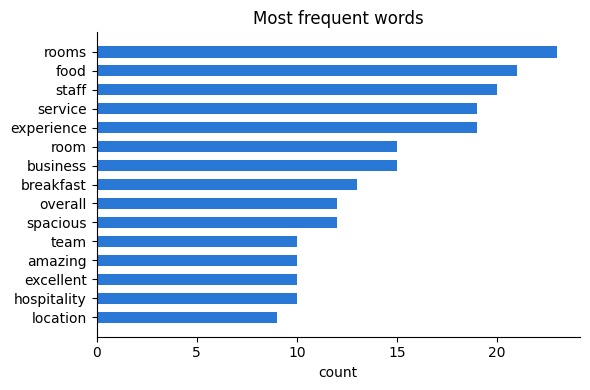


TEXT MINING: WORDS THAT SEPARATE 5 STAR FROM LOWER STAR REVIEWS
more typical of 5 star: staff, breakfast, lovely, awesome, wonderful, excellent, delicious, beautiful, checkin, meetings
more typical of <5 star: quite, old, slightly, business, especially, management, slow, big, service, close

TEXT MINING: TOPICS (NMF)
topic 0 : rooms, spacious, business, room, located, maintained, comfortable, overall
topic 1 : food, lovely, meetings, coffee, conferences, shop, excellent, inside
topic 2 : experience, team, event, time, entire, corporate, overall, service
topic 3 : breakfast, awesome, buffet, wonderful, attend, nice, ambience, conference
        n  stars  senti
topic                  
0      19   4.68   0.90
1       8   4.75   0.93
2      12   4.33   0.83
3       9   4.67   0.95


In [ ]:
STOP = list(CountVectorizer(stop_words="english").get_stop_words()) + [
    "hotel", "grand", "hyatt", "mumbai", "stay", "stayed", "place", "great", "good", "really", "just", "like", "got", "did", "went"]
tx = df.loc[ok, "text"].str.replace(r"check[- ]?(in|out)", lambda m: "check" + m.group(1), case=False, regex=True)

head("text mining: top words and phrases")
cv = CountVectorizer(stop_words=STOP, ngram_range=(1, 1), min_df=2)
w = pd.Series(np.asarray(cv.fit_transform(tx).sum(0)).ravel(), cv.get_feature_names_out()).sort_values(ascending=False)
print(w.head(15))
cv2 = CountVectorizer(stop_words=STOP, ngram_range=(2, 2), min_df=2)
b = pd.Series(np.asarray(cv2.fit_transform(tx).sum(0)).ravel(), cv2.get_feature_names_out()).sort_values(ascending=False)
print(b.head(12))

fig, ax = plt.subplots(figsize=(6, 4))
t = w.head(15)[::-1]
ax.barh(t.index, t.values, color=BLUE, height=0.6)
ax.set_xlabel("count")
ax.set_title("Most frequent words")
ax.spines[["top", "right"]].set_visible(False)
save("07_top_words")

try:
    from wordcloud import WordCloud
    wc = WordCloud(width=900, height=450, background_color="white", stopwords=set(STOP), colormap="Blues").generate(" ".join(tx))
    wc.to_file(f"{OUT}/08_wordcloud.png")
except ImportError:
    print("wordcloud not installed, skipped")

head("text mining: words that separate 5 star from lower star reviews")
tv = TfidfVectorizer(stop_words=STOP, min_df=2)
X = tv.fit_transform(tx)
y5 = (df.loc[ok, "rating"] == 5).values
diff = pd.Series(np.asarray(X[y5].mean(0)).ravel() - np.asarray(X[~y5].mean(0)).ravel(), tv.get_feature_names_out())
print("more typical of 5 star:", ", ".join(diff.sort_values(ascending=False).head(10).index))
print("more typical of <5 star:", ", ".join(diff.sort_values().head(10).index))

head("text mining: topics (NMF)")
K = 4
tv2 = TfidfVectorizer(stop_words=STOP, min_df=2, max_df=0.7)
X2 = tv2.fit_transform(tx)
nmf = NMF(n_components=K, init="nndsvda", random_state=0, max_iter=500)
Wt = nmf.fit_transform(X2)
terms = tv2.get_feature_names_out()
for k in range(K):
    print("topic", k, ":", ", ".join(terms[nmf.components_[k].argsort()[::-1][:8]]))
tp = df[ok].copy()
tp["topic"] = Wt.argmax(1)
print(tp.groupby("topic").agg(n=("rating", "size"), stars=("rating", "mean"), senti=("vader", "mean")).round(2))

7. predictive demo

In [ ]:
# With about 50 reviews this is a teaching demo, not a usable model.
# The baseline (always guess the majority class) is the number to beat.
head("predictive: can text predict a 5 star review")
y = (df.loc[ok, "rating"] == 5).astype(int).values
print("5 star share (majority baseline accuracy):", round(max(y.mean(), 1 - y.mean()), 2))
mn = min(y.sum(), (1 - y).sum())
ns = int(min(5, mn))
if ns >= 2:
    cvs = RepeatedStratifiedKFold(n_splits=ns, n_repeats=10, random_state=0)
    pipe_x = TfidfVectorizer(stop_words=STOP, ngram_range=(1, 2), min_df=2, sublinear_tf=True)
    clf =make_pipeline(pipe_x, LogisticRegression(class_weight="balanced", max_iter=1000))
    dm = make_pipeline(pipe_x, DummyClassifier(strategy="most_frequent"))
    for nm, mdl in (("logreg", clf), ("baseline", dm)):
        sc = cross_validate(mdl, tx.values, y, cv=cvs, scoring=["accuracy", "f1_macro"])
        print(nm, "accuracy %.2f | macro F1 %.2f" % (sc["test_accuracy"].mean(), sc["test_f1_macro"].mean()))
    clf.fit(tx.values, y)
    vec, lr = clf.steps[0][1], clf.steps[1][1]
    co = pd.Series(lr.coef_[0], vec.get_feature_names_out()).sort_values()
    print("pushes toward <5 star:", ", ".join(co.head(8).index))
    print("pushes toward 5 star :", ", ".join(co.tail(8).index[::-1]))
else:
    print("too few minority-class reviews for cross validation")


PREDICTIVE: CAN TEXT PREDICT A 5 STAR REVIEW
5 star share (majority baseline accuracy): 0.71
logreg accuracy 0.70 | macro F1 0.55
baseline accuracy 0.71 | macro F1 0.41
pushes toward <5 star: quite, business, especially, old, management, slightly, issue, close
pushes toward 5 star : staff, lovely, awesome, breakfast, excellent, fantastic, checkin, delicious


8. prescriptive summary

In [ ]:
# Turn the aspect table into a short priority list: things mentioned often
# AND scored low / complained about get fixed first.
head("prescriptive: priority list")
pr = at.copy()
pr["priority"] = (pr["reviews"] * pr["complaint_pct"] / 100).round(2)
pr = pr.sort_values("priority", ascending=False)
print(pr[["reviews", "mean", "complaint_pct", "priority"]])
top = pr.head(3).index.tolist()
print("\nfix first:", ", ".join(top))
print("protect (high volume, high sentiment):", ", ".join(at[at.reviews >= at.reviews.median()].sort_values("mean", ascending=False).head(3).index))
print("reply rate to reviews rated 3 or less: %d of %d" % (df[df.rating <= 3].has_resp.sum(), (df.rating <= 3).sum()))


PRESCRIPTIVE: PRIORITY LIST
                        reviews  mean  complaint_pct  priority
asp                                                           
upkeep and cleanliness       14  0.35          47.37      6.63
room                         26  0.36          14.29      3.72
food and dining              35  0.51           9.26      3.24
staff and service            32  0.52           8.62      2.76
ambience and design          16  0.56          10.53      1.68
location                     15  0.53          11.11      1.67
check-in and billing          8  0.35          18.18      1.45
value for money               3  0.33          25.00      0.75
events and facilities        20  0.41           2.86      0.57

fix first: upkeep and cleanliness, room, food and dining
protect (high volume, high sentiment): ambience and design, staff and service, food and dining
reply rate to reviews rated 3 or less: 4 of 4


9. save

In [ ]:
cols = ["file", "name", "rating", "rooms", "service", "location", "purpose", "party", "era", "age_y",
        "words", "vader", "senti", "has_resp", "responder", "offtopic", "text"]
df[cols].to_csv(f"{OUT}/reviews_clean.csv", index=False)
sd.assign(asp=sd.asp.str.join("; ")).to_csv(f"{OUT}/sentences.csv", index=False)
print("\nsaved files in", OUT)


saved files in out


10. summary dashboard

/tmp/ipykernel_2950/1809275445.py:134: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(rect=[0, 0, 1, 0.96])


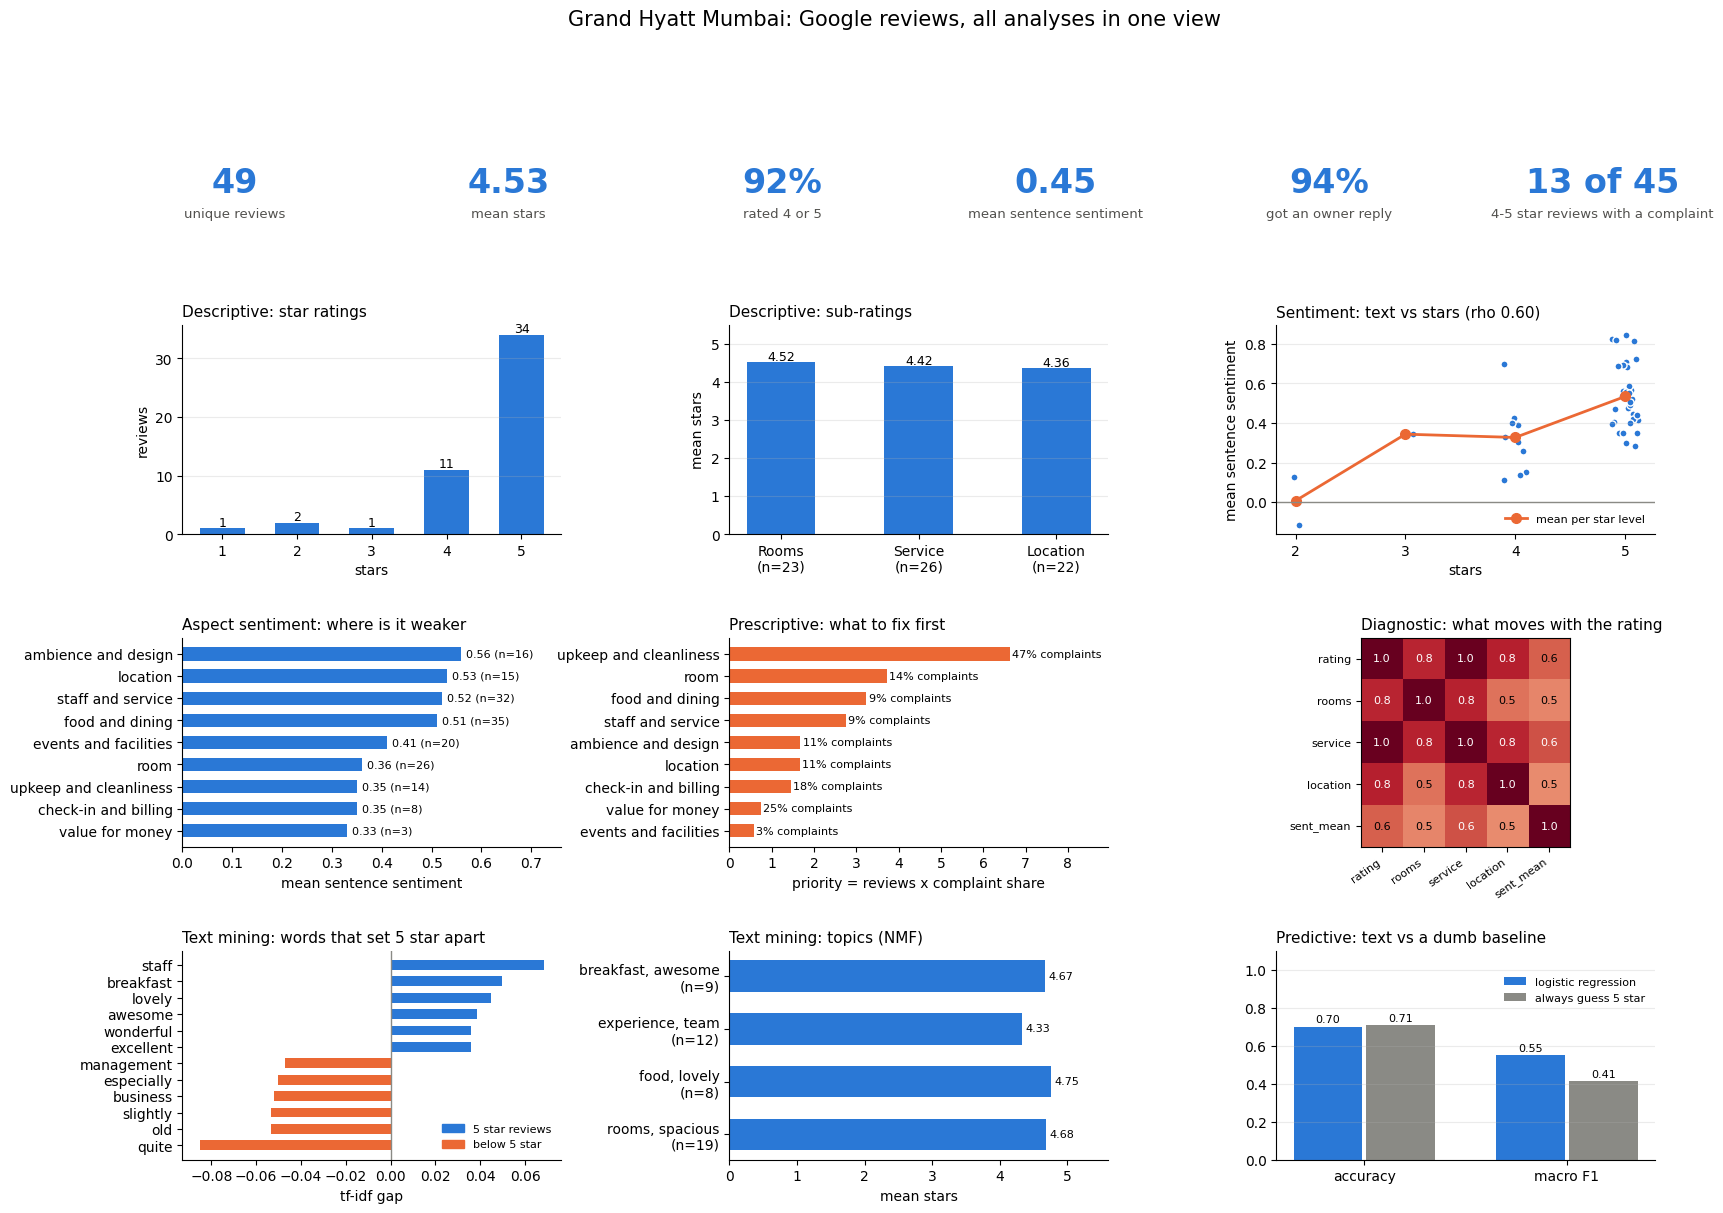

In [ ]:
# Final summary figure. Every number comes from variables made in the cells above.
nn = len(df)
g45 = sd[sd.rating >= 4].groupby("i").complaint.any()
n_hid, n_g45 = int(g45.sum()), len(g45)
m = ok & df.sent_mean.notna()
rho2, p2 = stats.spearmanr(df.loc[m, "rating"], df.loc[m, "sent_mean"])

# model vs baseline, same setup as the predictive cell
md = None
if "cvs" in globals():
    sc1 = cross_validate(clf, tx.values, y, cv=cvs, scoring=["accuracy", "f1_macro"])
    sc0 = cross_validate(dm, tx.values, y, cv=cvs, scoring=["accuracy", "f1_macro"])
    md = {"logreg": [sc1["test_accuracy"].mean(), sc1["test_f1_macro"].mean()],
          "baseline": [sc0["test_accuracy"].mean(), sc0["test_f1_macro"].mean()]}

from matplotlib.patches import Patch
fig = plt.figure(figsize=(19, 13))
gs = fig.add_gridspec(4, 6, height_ratios=[0.3, 1, 1, 1], hspace=0.6, wspace=1.6)

kpi = [(str(nn), "unique reviews"),
       (f"{df.rating.mean():.2f}", "mean stars"),
       (f"{df.good.mean() * 100:.0f}%", "rated 4 or 5"),
       (f"{df.sent_mean.mean():.2f}", "mean sentence sentiment"),
       (f"{df.has_resp.mean() * 100:.0f}%", "got an owner reply"),
       (f"{n_hid} of {n_g45}", "4-5 star reviews with a complaint")]
for k, (v, lab) in enumerate(kpi):
    a = fig.add_subplot(gs[0, k])
    a.axis("off")
    a.text(0.5, 0.62, v, ha="center", va="center", fontsize=24, fontweight="bold", color=BLUE)
    a.text(0.5, 0.12, lab, ha="center", va="center", fontsize=9.5, color="#52514e")

a = fig.add_subplot(gs[1, 0:2])
c = df.rating.value_counts().reindex([1, 2, 3, 4, 5], fill_value=0)
a.bar(c.index.astype(str), c.values, color=BLUE, width=0.6)
for x, v in zip(c.index.astype(str), c.values):
    a.text(x, v + 0.4, str(v), ha="center", fontsize=9)
a.set_title("Descriptive: star ratings", fontsize=11, loc="left")
a.set_xlabel("stars")
a.set_ylabel("reviews")
style(a)

a = fig.add_subplot(gs[1, 2:4])
sm = df[subs].mean()
a.bar([s.title() + f"\n(n={int(df[s].notna().sum())})" for s in subs], sm.values, color=BLUE, width=0.5)
for i, v in enumerate(sm.values):
    a.text(i, v + 0.05, f"{v:.2f}", ha="center", fontsize=9)
a.set_ylim(0, 5.5)
a.set_ylabel("mean stars")
a.set_title("Descriptive: sub-ratings", fontsize=11, loc="left")
style(a)

a = fig.add_subplot(gs[1, 4:6])
d1 = df[m]
rs = np.random.RandomState(0)
a.scatter(d1.rating + rs.uniform(-0.12, 0.12, len(d1)), d1.sent_mean, s=26, color=BLUE, edgecolor="white", linewidth=1)
mm = d1.groupby("rating").sent_mean.mean()
a.plot(mm.index, mm.values, color=ORG, marker="o", lw=2, ms=7, label="mean per star level")
a.axhline(0, color=GRAY, lw=1)
a.set_xticks([2, 3, 4, 5])
a.set_xlabel("stars")
a.set_ylabel("mean sentence sentiment")
a.set_title(f"Sentiment: text vs stars (rho {rho2:.2f})", fontsize=11, loc="left")
a.legend(frameon=False, fontsize=8, loc="lower right")
style(a)

a = fig.add_subplot(gs[2, 0:2])
t = at.sort_values("mean")
a.barh(t.index, t["mean"], color=BLUE, height=0.6)
for y_, (v, k) in enumerate(zip(t["mean"], t["reviews"])):
    a.text(v + 0.01, y_, f"{v:.2f} (n={k})", va="center", fontsize=8)
a.set_xlim(0, t["mean"].max() + 0.2)
a.set_xlabel("mean sentence sentiment")
a.set_title("Aspect sentiment: where is it weaker", fontsize=11, loc="left")
a.spines[["top", "right"]].set_visible(False)

a = fig.add_subplot(gs[2, 2:4])
t = pr.sort_values("priority")
a.barh(t.index, t["priority"], color=ORG, height=0.6)
for y_, (v, cpc) in enumerate(zip(t["priority"], t["complaint_pct"])):
    a.text(v + 0.05, y_, f"{cpc:.0f}% complaints", va="center", fontsize=8)
a.set_xlim(0, t["priority"].max() * 1.35)
a.set_xlabel("priority = reviews x complaint share")
a.set_title("Prescriptive: what to fix first", fontsize=11, loc="left")
a.spines[["top", "right"]].set_visible(False)

a = fig.add_subplot(gs[2, 4:6])
sel = ["rating", "rooms", "service", "location", "sent_mean"]
cc = cm.loc[sel, sel]
a.imshow(cc.values, cmap="RdBu_r", vmin=-1, vmax=1)
a.set_xticks(range(len(sel)), sel, rotation=35, ha="right", fontsize=8)
a.set_yticks(range(len(sel)), sel, fontsize=8)
for i in range(len(sel)):
    for j in range(len(sel)):
        v = cc.values[i, j]
        if not np.isnan(v):
            a.text(j, i, f"{v:.1f}", ha="center", va="center", fontsize=8, color="white" if abs(v) > 0.6 else "black")
a.set_title("Diagnostic: what moves with the rating", fontsize=11, loc="left")

a = fig.add_subplot(gs[3, 0:2])
dd = pd.concat([diff.sort_values().head(6), diff.sort_values().tail(6)])
a.barh(dd.index, dd.values, color=[ORG if v < 0 else BLUE for v in dd.values], height=0.6)
a.axvline(0, color=GRAY, lw=1)
a.set_xlabel("tf-idf gap")
a.set_title("Text mining: words that set 5 star apart", fontsize=11, loc="left")
a.legend(handles=[Patch(color=BLUE, label="5 star reviews"), Patch(color=ORG, label="below 5 star")], frameon=False, fontsize=8, loc="lower right")
a.spines[["top", "right"]].set_visible(False)

a = fig.add_subplot(gs[3, 2:4])
tg = tp.groupby("topic").agg(n=("rating", "size"), stars=("rating", "mean"))
lab = [", ".join(terms[nmf.components_[k].argsort()[::-1][:2]]) + f"\n(n={int(tg.loc[k, 'n'])})" for k in tg.index]
a.barh(lab, tg["stars"], color=BLUE, height=0.6)
for y_, v in enumerate(tg["stars"]):
    a.text(v + 0.05, y_, f"{v:.2f}", va="center", fontsize=8)
a.set_xlim(0, 5.6)
a.set_xlabel("mean stars")
a.set_title("Text mining: topics (NMF)", fontsize=11, loc="left")
a.spines[["top", "right"]].set_visible(False)

a = fig.add_subplot(gs[3, 4:6])
if md:
    xs = np.arange(2)
    a.bar(xs - 0.18, md["logreg"], 0.34, color=BLUE, label="logistic regression")
    a.bar(xs + 0.18, md["baseline"], 0.34, color=GRAY, label="always guess 5 star")
    for i in range(2):
        a.text(i - 0.18, md["logreg"][i] + 0.02, f"{md['logreg'][i]:.2f}", ha="center", fontsize=8)
        a.text(i + 0.18, md["baseline"][i] + 0.02, f"{md['baseline'][i]:.2f}", ha="center", fontsize=8)
    a.set_xticks(xs, ["accuracy", "macro F1"])
    a.set_ylim(0, 1.1)
    a.legend(frameon=False, fontsize=8, loc="upper right", bbox_to_anchor=(1.0, 0.92))
a.set_title("Predictive: text vs a dumb baseline", fontsize=11, loc="left")
style(a)

fig.suptitle("Grand Hyatt Mumbai: Google reviews, all analyses in one view", fontsize=15, y=0.995)
plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.savefig(f"{OUT}/00_summary_dashboard.png", dpi=150)
if SHOW:
    plt.show()
plt.close()

11. how the analyses connect

In [ ]:
# How the analyses connect: each step uses the result of the one before it.
big = at[at.reviews >= 8]
weak, strong = big["mean"].idxmin(), big["mean"].idxmax()
cn = cp.groupby("asp").size().sort_values(ascending=False)
lo_w = ", ".join(diff.sort_values().head(5).index)
top3 = ", ".join(pr.index[:3])
if md:
    mtxt = f"accuracy {md['logreg'][0]:.2f} vs baseline {md['baseline'][0]:.2f}"
    mlead = "no real gain over guessing, so the conclusions rest on the aspect and complaint steps"
else:
    mtxt, mlead = "not run", ""

rows = [
    ("1 Descriptive", "How good are the ratings?",
     f"mean {df.rating.mean():.2f}, {df.good.mean() * 100:.0f}% are 4-5 star",
     "stars alone hide detail, so read the text"),
    ("2 Sentiment", "Does the text agree with the stars?",
     f"spearman {rho2:.2f} between stars and sentence sentiment",
     "text is a usable signal, so break it down by topic"),
    ("3 Aspect sentiment", "Which part of the stay is weaker?",
     f"weakest: {weak} ({big.loc[weak, 'mean']:.2f}), strongest: {strong} ({big.loc[strong, 'mean']:.2f}), topics with 8+ reviews",
     "low scoring topics are where complaints should cluster"),
    ("4 Diagnostic", "Where do complaints hide?",
     f"{n_hid} of {n_g45} reviews rated 4-5 still contain a complaint; most complaints about {cn.index[0]}, {cn.index[1]}",
     "happy guests still flag the same issues, so stars understate them"),
    ("5 Text mining", "Do the raw words agree?",
     f"words typical of below-5-star reviews: {lo_w}",
     "same themes (old, slow) appear without any keyword list"),
    ("6 Predictive", "Can text predict a 5 star review?", mtxt, mlead),
    ("7 Prescriptive", "What should be fixed first?",
     f"top priorities: {top3}",
     "combines how often a topic is mentioned with how often it is complained about"),
]
tb = pd.DataFrame(rows, columns=["step", "question", "result", "leads to"])
pd.set_option("display.max_colwidth", 200)
print(tb.to_string(index=False))

lines = [
    "SUMMARY",
    f"{nn} unique reviews, mean {df.rating.mean():.2f} stars, {df.good.mean() * 100:.0f}% rated 4-5.",
    f"Text and stars agree (spearman {rho2:.2f}), so sentiment is a fair measure of satisfaction.",
    f"Strongest topic: {strong}. Weakest topic: {weak}.",
    f"{n_hid} of {n_g45} reviews rated 4-5 still mention a problem, mostly about {cn.index[0]} and {cn.index[1]}.",
    f"Fix first: {top3}.",
    "",
    "CAVEATS",
    f"Only {nn} reviews, so p-values and the model are rough.",
    "Aspects come from keyword lists and complaints from a keyword plus VADER rule, so they are heuristics.",
    "Sub-ratings exist for only about half the reviews.",
    "Dates are coarse (Google gives '7 years ago'), so time trends are approximate.",
    "One off-topic review (a hotel group land dispute) is left out of sentiment and aspect work.",
]
print()
print("\n".join(lines))
open(f"{OUT}/summary.txt", "w").write("\n".join(lines))
tb.to_csv(f"{OUT}/connections_table.csv", index=False)

              step                            question                                                                                              result                                                                              leads to
     1 Descriptive           How good are the ratings?                                                                         mean 4.53, 92% are 4-5 star                                             stars alone hide detail, so read the text
       2 Sentiment Does the text agree with the stars?                                                  spearman 0.60 between stars and sentence sentiment                                    text is a usable signal, so break it down by topic
3 Aspect sentiment   Which part of the stay is weaker? weakest: check-in and billing (0.35), strongest: ambience and design (0.56), topics with 8+ reviews                                low scoring topics are where complaints should cluster
      4 Diagnostic           Where d

12. where the problems are

In [ ]:
# Written findings: where the problems are. Numbers come from the cells above.
import textwrap


def wrap(t, ind="   "):
    return textwrap.fill(t, 95, initial_indent=ind, subsequent_indent=ind)


out_ = ["WHERE THE PROBLEMS ARE", ""]
for k, nm in enumerate(pr.index[:3], 1):
    r = pr.loc[nm]
    c_ = cp[cp.asp == nm].sort_values("score")
    st_ = ", ".join(f"{int(s)} star" for s in sorted(c_.rating.unique()))
    out_.append(f"{k}. {nm.upper()}")
    gap_ = at["mean"].max() - r["mean"]
    lvl_ = (f"Mean sentiment is {r['mean']:.2f}, well below the best topic at {at['mean'].max():.2f}. " if gap_ > 0.1
            else f"Sentiment is still fairly high ({r['mean']:.2f}); it ranks here because so many guests mention it. ")
    out_.append(wrap(f"{int(r.reviews)} reviews mention it and {r.complaint_pct:.0f}% of those sentences are complaints. "
                     + lvl_ + f"The complaints come from {st_} reviews."))
    if len(c_):
        q_ = c_.iloc[0]
        out_.append(wrap(f'Example: "{q_.sent[:150]}" ({int(q_.rating)} star, {q_["name"]})'))
    out_.append("")

hid_ = cp[cp.rating >= 4].asp.value_counts()
out_.append("PROBLEMS HIDDEN INSIDE GOOD REVIEWS")
out_.append(wrap(f"{n_hid} of {n_g45} reviews rated 4-5 still contain a complaint. "
                 f"Most are about: " + ", ".join(f"{i} ({v})" for i, v in hid_.head(3).items()) + ". "
                 "The star rating alone would miss these."))
out_.append("")

sm_ = at[(at.reviews < 8) | ~at.index.isin(pr.index[:3])]
small = at[at.reviews < 8].index.tolist()
out_.append("SMALLER ISSUES")
bl = cp[cp.asp == "check-in and billing"]
if len(bl):
    b0 = bl.sort_values("score").iloc[0]
    out_.append(wrap(f"check-in and billing: {len(bl)} complaint sentences, from {', '.join(sorted({str(int(s)) + ' star' for s in bl.rating}))} reviews."))
    out_.append(wrap(f'Example: "{b0.sent[:150]}" ({int(b0.rating)} star, {b0["name"]})'))
if small:
    out_.append(wrap("Too few reviews to judge: " + ", ".join(small) + "."))
out_.append("")

good_ = at[at.reviews >= 8].sort_values("mean", ascending=False).head(3)
out_.append("WHAT IS WORKING")
out_.append(wrap("Highest sentiment: " + ", ".join(f"{i} ({v:.2f})" for i, v in good_["mean"].items()) +
                 f". {df.good.mean() * 100:.0f}% of all reviews are 4-5 star."))
out_.append("")
out_.append("Note: complaints are found with keywords plus VADER, so a few sentences may be flagged wrongly.")
print("\n".join(out_))
open(f"{OUT}/problems.txt", "w").write("\n".join(out_))

WHERE THE PROBLEMS ARE

1. UPKEEP AND CLEANLINESS
   14 reviews mention it and 47% of those sentences are complaints. Mean sentiment is 0.35,
   well below the best topic at 0.56. The complaints come from 3 star, 4 star reviews.
   Example: "Do not mean to nitpick but the mosquitos were a menace." (4 star, Shuvayu
   Mukherjee)

2. ROOM
   26 reviews mention it and 14% of those sentences are complaints. Mean sentiment is 0.36,
   well below the best topic at 0.56. The complaints come from 4 star, 5 star reviews.
   Example: "The hotel has a slightly worn-out look and feel, especially in the Residences
   block." (4 star, Akhil Mohan)

3. FOOD AND DINING
   35 reviews mention it and 9% of those sentences are complaints. Sentiment is still fairly
   high (0.51); it ranks here because so many guests mention it. The complaints come from 2
   star, 4 star reviews.
   Example: "Breakfast is ok for Indian nationals, but not adapted to Europeans, the selection
   is small and not well made." (

1784